# BGIS Esports Team Performance Analyzer
Classification-focused ML mini project using BGIS 2026 overall team statistics.

**Target:** `top_5_team` (1 = overall rank 1–5; 0 = otherwise).

**Important limitation:** This starter CSV has only 19 aggregated team rows, not match-by-match data. It is useful for demonstrating the workflow, but too small for reliable generalization. For a stronger project, collect one row per team per match.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42

## 2. Load CSV (relative path)

In [2]:
DATA_PATH = Path("data") / "BGIS_2026_Team_Statistics.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Missing {DATA_PATH.resolve()}. Keep the data folder next to this notebook.")
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (19, 14)


,rank,team,total_points,matches_played,eliminations,placement_points,avg_place_rank,avg_eliminations,avg_placement_points,avg_total_points,top5_finishes,top8_finishes,outside_top8_finishes,top_5_team
0,1,Team SouL,345,34,110,235,6.79,3.24,6.91,10.15,5,3,5,1
1,2,GodLike Esports,331,46,99,232,8.00,2.15,5.04,7.20,2,3,6,1
2,3,Genesis Esports,312,34,90,222,7.68,2.65,6.53,9.18,4,2,2,1
3,4,Vasista Esports,288,46,104,184,8.15,2.26,4.00,6.26,4,5,1,1
4,5,Wyld Fangs,284,46,95,189,8.35,2.07,4.11,6.17,3,1,4,1


## 3. Explore data

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
rank,19.0,NaN,NaN,NaN,10.0,5.627314,1.0,5.5,10.0,14.5,19.0
team,19,19,Team SouL,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_points,19.0,NaN,NaN,NaN,251.842105,51.722833,159.0,218.0,248.0,283.0,345.0
matches_played,19.0,NaN,NaN,NaN,38.105263,7.225685,28.0,34.0,34.0,46.0,46.0
eliminations,19.0,NaN,NaN,NaN,81.315789,16.716767,55.0,67.0,85.0,95.5,110.0
placement_points,19.0,NaN,NaN,NaN,170.526316,38.265692,97.0,144.0,176.0,192.5,235.0
avg_place_rank,19.0,NaN,NaN,NaN,8.26,0.78468,6.79,7.895,8.25,8.52,10.41
avg_eliminations,19.0,NaN,NaN,NaN,2.173684,0.462748,1.3,1.935,2.12,2.425,3.24
avg_placement_points,19.0,NaN,NaN,NaN,4.517895,0.931853,3.43,4.05,4.24,4.595,6.91
avg_total_points,19.0,NaN,NaN,NaN,6.690526,1.2951,4.74,6.1,6.32,6.97,10.15


,missing_values
rank,0
team,0
total_points,0
matches_played,0
eliminations,0
placement_points,0
avg_place_rank,0
avg_eliminations,0
avg_placement_points,0
avg_total_points,0


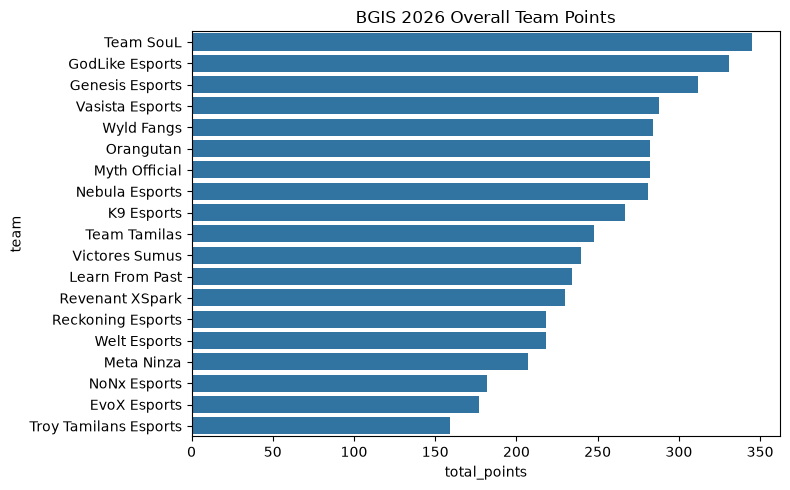

In [3]:
display(df.describe(include="all").T)
display(df.isna().sum().to_frame("missing_values"))
plt.figure(figsize=(8,5))
sns.barplot(data=df.sort_values("total_points", ascending=False), x="total_points", y="team")
plt.title("BGIS 2026 Overall Team Points")
plt.tight_layout()
plt.show()

## 4. Prepare features and target

In [4]:
target = "top_5_team"
# Exclude team identity, rank, total points, and target to reduce direct leakage.
X = df.drop(columns=["team", "rank", "total_points", target])
y = df[target]
print("Features:", X.columns.tolist())
print("Target counts:")
display(y.value_counts())

Features: ['matches_played', 'eliminations', 'placement_points', 'avg_place_rank', 'avg_eliminations', 'avg_placement_points', 'avg_total_points', 'top5_finishes', 'top8_finishes', 'outside_top8_finishes']
Target counts:


top_5_team
0    14
1     5
Name: count, dtype: int64

## 5. Train/test split and classification models

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "SVM (RBF)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "KNN (k=3)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=3))
    ])
}
results=[]
for name, model in models.items():
    model.fit(X_train, y_train)
    pred=model.predict(X_test)
    results.append({"Model":name, "Accuracy":accuracy_score(y_test,pred),
                    "Precision":precision_score(y_test,pred,zero_division=0),
                    "Recall":recall_score(y_test,pred,zero_division=0),
                    "F1-score":f1_score(y_test,pred,zero_division=0)})
results_df=pd.DataFrame(results).sort_values("F1-score",ascending=False)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.833,1.0,0.5,0.667
1,SVM (RBF),0.833,1.0,0.5,0.667
2,KNN (k=3),0.667,0.0,0.0,0.000


## 6. Reports and confusion matrices

\n Logistic Regression
              precision    recall  f1-score   support

   Not top 5       0.80      1.00      0.89         4
       Top 5       1.00      0.50      0.67         2

    accuracy                           0.83         6
   macro avg       0.90      0.75      0.78         6
weighted avg       0.87      0.83      0.81         6



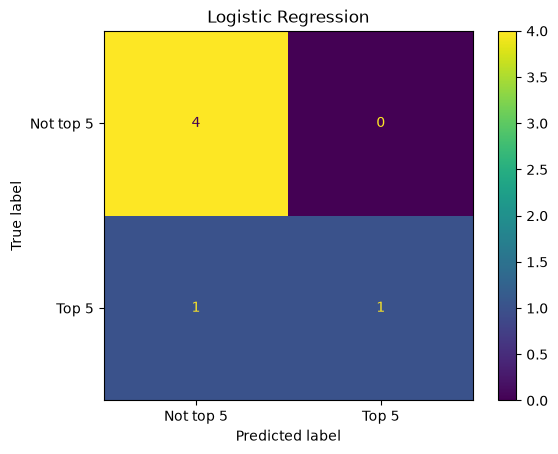

\n SVM (RBF)
              precision    recall  f1-score   support

   Not top 5       0.80      1.00      0.89         4
       Top 5       1.00      0.50      0.67         2

    accuracy                           0.83         6
   macro avg       0.90      0.75      0.78         6
weighted avg       0.87      0.83      0.81         6



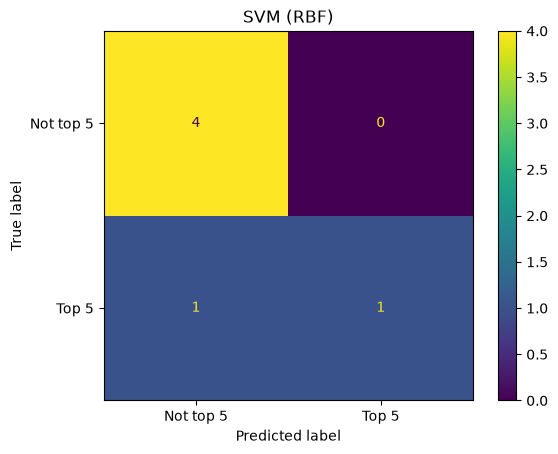

\n KNN (k=3)
              precision    recall  f1-score   support

   Not top 5       0.67      1.00      0.80         4
       Top 5       0.00      0.00      0.00         2

    accuracy                           0.67         6
   macro avg       0.33      0.50      0.40         6
weighted avg       0.44      0.67      0.53         6



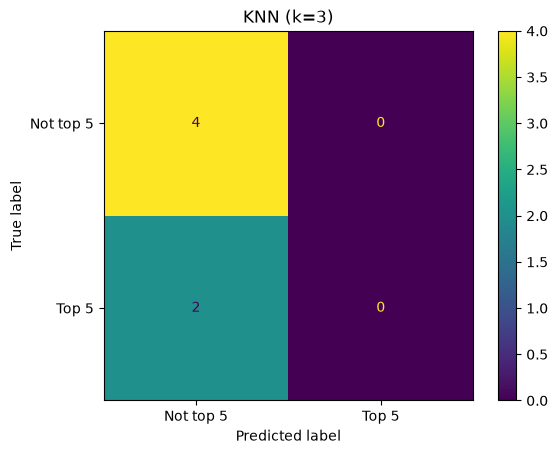

In [6]:
for name, model in models.items():
    pred=model.predict(X_test)
    print("\\n", name)
    print(classification_report(y_test,pred,labels=[0,1],target_names=["Not top 5","Top 5"],zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=[0,1],display_labels=["Not top 5","Top 5"])
    plt.title(name)
    plt.show()

## 7. K-Means clustering

In [7]:
# Unsupervised clustering: target is not used as an input.
prep=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())])
X_scaled=prep.fit_transform(X)
km=KMeans(n_clusters=3,random_state=RANDOM_STATE,n_init=10)
df["cluster"]=km.fit_predict(X_scaled)
display(df.groupby("cluster").agg(team_count=("team","count"), average_points=("total_points","mean"), top5_count=("top_5_team","sum"), top5_rate=("top_5_team","mean")).round(3))
display(df[["team","total_points","top_5_team","cluster"]].sort_values("cluster"))

,team_count,average_points,top5_count,top5_rate
cluster,,,,
0,8,275.875,3,0.375
1,3,313.000,2,0.667
2,8,204.875,0,0.000


,team,total_points,top_5_team,cluster
1,GodLike Esports,331,1,0
3,Vasista Esports,288,1,0
6,Myth Official,282,0,0
4,Wyld Fangs,284,1,0
7,Nebula Esports,281,0,0
11,Learn From Past,234,0,0
10,Victores Sumus,240,0,0
8,K9 Esports,267,0,0
5,Orangutan,282,0,1
2,Genesis Esports,312,1,1


## 8. Conclusion

Use the actual metrics printed by the notebook; do not claim a model is best before running it. With 19 aggregate rows, results are unstable. This is a prototype classification exercise, not a reliable future-tournament predictor.

**Source:** Liquipedia, *Battlegrounds Mobile India Series 2026: Team Statistics*: https://liquipedia.net/pubgmobile/Battlegrounds_Mobile_India_Series/2026/Statistics

**Label definition:** `top_5_team = 1` for overall rank 1–5, else 0. This label is derived from final standings.